### ДЗ 2: классификация изображений

In [2]:
# импорт библиотек

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset, Subset, random_split

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import copy
from pathlib import Path
from PIL import Image

from scipy import ndimage

In [3]:
# фиксируем seed
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Определяем устройство: GPU, если доступен, иначе CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.set_num_threads(4)

Используемое устройство: cpu


In [4]:
# обрезаем белый фон

def crop_foreground(image):
    # переводим в оттенки серого
    image = image.convert("L")
    pixels = np.asarray(image)

    # определяем цвет фона
    background = int(np.median(np.concatenate([pixels[0], pixels[-1], pixels[:, 0], pixels[:, -1]])))

    # отделяем объект от фона
    mask = np.abs(pixels.astype(np.int16) - background) > 15
    mask = ndimage.binary_closing(mask, iterations=2)

    # самый большой связный объект
    components, count = ndimage.label(mask)
    if count == 0:
        return image

    sizes = np.bincount(components.ravel())
    sizes[0] = 0
    largest = int(sizes.argmax())

    # проверка размера найденного объекта
    if sizes[largest] < pixels.size * 0.02:
        return image

    ys, xs = np.where(components == largest)
    x0, x1 = int(xs.min()), int(xs.max() + 1)
    y0, y1 = int(ys.min()), int(ys.max() + 1)

    # добавляем отступы
    margin = max(2, int(0.04 * max(x1 - x0, y1 - y0)))
    x0 = max(0, x0 - margin)
    y0 = max(0, y0 - margin)
    x1 = min(image.width, x1 + margin)
    y1 = min(image.height, y1 + margin)

    cropped = image.crop((x0, y0, x1, y1))

    # дополняем до квадрата
    side = max(cropped.size)
    square = Image.new("L", (side, side), color=background)
    square.paste(cropped, (
        (side - cropped.width) // 2,
        (side - cropped.height) // 2
    ))
    return square

In [5]:
# путь к папке с данными
data_dir = Path("mri_classification_dataset")

# преобразование данных
image_size = 128
base_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Lambda(crop_foreground),
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
])

In [6]:
train_dataset = datasets.ImageFolder(data_dir/"train", transform=base_transform)
print('Соответствие классов:', train_dataset.class_to_idx)

val_dataset = datasets.ImageFolder(data_dir/"val", transform=base_transform)
print('Соответствие классов:', val_dataset.class_to_idx)

print(f"Размер train: {len(train_dataset)}")
print(f"Размер val: {len(val_dataset)}")

Соответствие классов: {'class_0': 0, 'class_1': 1, 'class_2': 2, 'class_3': 3, 'class_4': 4}
Соответствие классов: {'class_0': 0, 'class_1': 1, 'class_2': 2, 'class_3': 3, 'class_4': 4}
Размер train: 1390
Размер val: 298


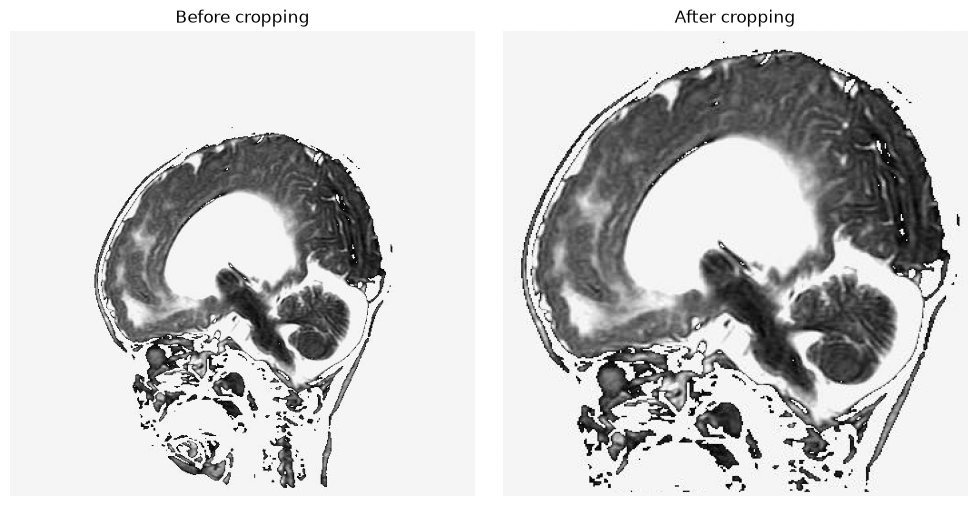

До обрезки: (512, 512)
После обрезки: (348, 348)


In [7]:
# проверка функции обрезки

image_path, label = train_dataset.samples[2]
image = Image.open(image_path)
cropped = crop_foreground(image)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap='gray')
axes[0].set_title("Before cropping")
axes[0].axis('off')
axes[1].imshow(cropped, cmap='gray')
axes[1].set_title("After cropping")
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("До обрезки:", image.size)
print("После обрезки:", cropped.size)

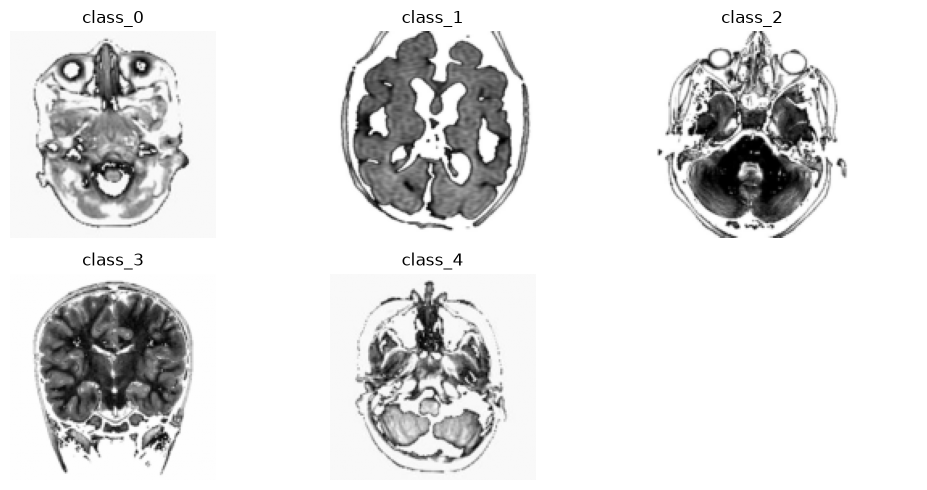

In [8]:
# посмотрим по одному изображению из каждого класса
fig, axes = plt.subplots(2, 3, figsize=(10, 5))
classes = train_dataset.classes  # список названий классов

for i, ax in enumerate(axes.flat):
    if i < len(classes):
        index = train_dataset.targets.index(i)
        img, label = train_dataset[index]
        ax.imshow(img.squeeze(0).numpy(), cmap="gray")
        ax.set_title(classes[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [9]:
# создание DataLoader
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)

Данные подготовлены. Дальше - построение свёрточной нейронной сети.

In [10]:
# класс взят из обучающего ноутбука, но изменен под задачу

class CNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),

            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),


            nn.AdaptiveAvgPool2d((4, 4)),  # уменьшаем размер признаков до 4 x 4
        )
        self.fc_layers = nn.Sequential(
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(), # ReLU слой, иначе получим два подряд линейных слоя, в чем нет смысла - их работа моделируется одним линейным слоем
            nn.Dropout(0.1),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1)  # вытягиваем изображение в вектор размера 128 x 4 x 4, чтобы подать на вход полносвязному слою
        x = self.fc_layers(x)
        return x

model = CNN(num_classes=5).to(device)
print(model)

CNN(
  (conv_layers): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(32, 64, kernel

In [11]:
# оптимизатор и функция потерь

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [12]:
# обучение нейросети (взят из обучающего ноутбука)

epochs = 25
train_loss_history = []
val_acc_history = []
best_acc = -1.0
best_state = None
best_epoch = 0

for epoch in range(epochs):
    # Переключаем модель в режим обучения (важно для Dropout, BatchNorm и т.п.)
    model.train()
    running_loss = 0.0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Обнуляем градиенты, чтобы они не накапливались от прошлых итераций
        optimizer.zero_grad()

        # Шаг 1. Прямой проход: получаем предсказания модели
        outputs = model(inputs)

        # Шаг 2. Вычисляем потери между предсказаниями и истинными метками
        loss = criterion(outputs, labels)

        # Шаг 3. Обратный проход: вычисляем градиенты по всем параметрам
        loss.backward()

        # Шаг 4. Обновляем веса с помощью оптимизатора
        optimizer.step()

        # Суммируем потери для отчёта за эпоху
        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_dataset)
    train_loss_history.append(epoch_loss)

    # Переключаем модель в режим оценки качества
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():  # отключаем расчёт градиентов для ускорения вычислений
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    val_acc = correct / total
    val_acc_history.append(val_acc)
    if val_acc > best_acc:
        best_acc = val_acc
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f}, Val Acc: {val_acc:.4f}")

model.load_state_dict(best_state)

Epoch 1/25, Loss: 1.4821, Val Acc: 0.2248
Epoch 2/25, Loss: 0.8421, Val Acc: 0.3255
Epoch 3/25, Loss: 0.4752, Val Acc: 0.6711
Epoch 4/25, Loss: 0.3048, Val Acc: 0.7617
Epoch 5/25, Loss: 0.2333, Val Acc: 0.9430
Epoch 6/25, Loss: 0.2097, Val Acc: 0.8792
Epoch 7/25, Loss: 0.1245, Val Acc: 0.9329
Epoch 8/25, Loss: 0.1191, Val Acc: 0.9329
Epoch 9/25, Loss: 0.0696, Val Acc: 0.9631
Epoch 10/25, Loss: 0.0461, Val Acc: 0.9262
Epoch 11/25, Loss: 0.0585, Val Acc: 0.9564
Epoch 12/25, Loss: 0.0674, Val Acc: 0.9362
Epoch 13/25, Loss: 0.0271, Val Acc: 0.9631
Epoch 14/25, Loss: 0.0175, Val Acc: 0.9799
Epoch 15/25, Loss: 0.0132, Val Acc: 0.9832
Epoch 16/25, Loss: 0.0095, Val Acc: 0.9765
Epoch 17/25, Loss: 0.0052, Val Acc: 0.9832
Epoch 18/25, Loss: 0.0045, Val Acc: 0.9899
Epoch 19/25, Loss: 0.0044, Val Acc: 0.9899
Epoch 20/25, Loss: 0.0063, Val Acc: 0.8691
Epoch 21/25, Loss: 0.0146, Val Acc: 0.9497
Epoch 22/25, Loss: 0.0480, Val Acc: 0.7349
Epoch 23/25, Loss: 0.0485, Val Acc: 0.9698
Epoch 24/25, Loss: 0

<All keys matched successfully>

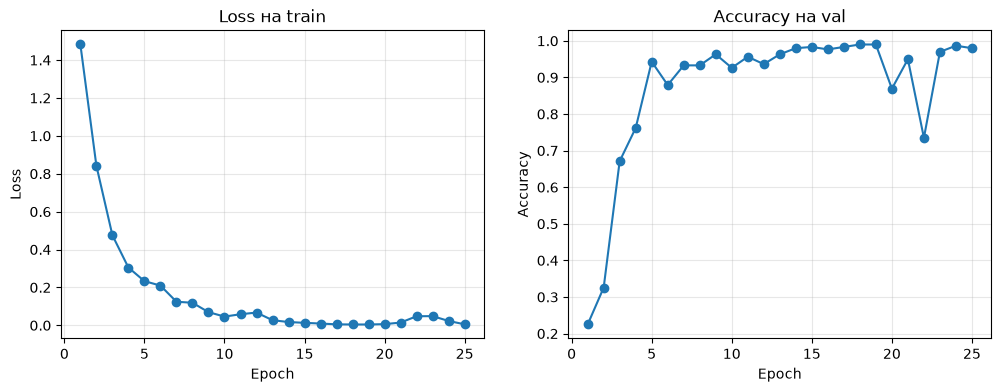

In [13]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), train_loss_history, marker='o')
plt.title('Loss на train')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), val_acc_history, marker='o')
plt.title('Accuracy на val')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True, alpha=0.3)

plt.show()

Некоторые ячейки с анализом ошибок были удалены, т.к. больше относились к отладочной информации. Они использовались для того, чтобы понять, на каких классах модель показывает наихудшее предсказание (такими были 1 и 4 классы).

In [14]:
# анализ ошибок на validation
model.eval()

all_labels = []
all_preds = []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_preds.extend(preds.cpu().numpy())

# матрица ошибок
confusion = np.zeros((5, 5), dtype=int)

for label, pred in zip(all_labels, all_preds):
    confusion[label, pred] += 1

print(pd.DataFrame(
    confusion,
    index=classes,
    columns=classes
))

         class_0  class_1  class_2  class_3  class_4
class_0       60        0        0        0        0
class_1        1       58        0        0        0
class_2        0        0       58        0        2
class_3        0        0        0       60        0
class_4        0        0        0        0       59


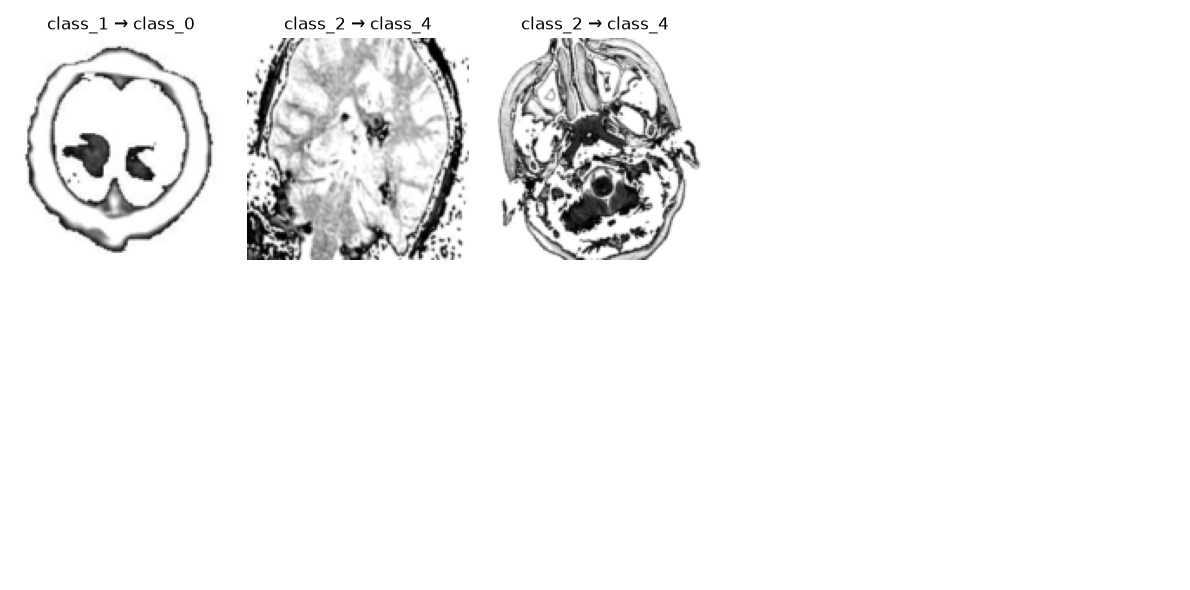

In [15]:
# посмотрим на ошибки модели
errors = [
    i for i in range(len(all_labels))
    if all_labels[i] != all_preds[i]
]

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    if i < len(errors):
        index = errors[i]
        img, label = val_dataset[index]

        ax.imshow(img.squeeze(0).numpy(), cmap='gray')
        ax.set_title(f"{classes[label]} → {classes[all_preds[index]]}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [40]:
# применим аугментацию данных

train_transform_aug = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
])

# отдельный экземпляр датасета
train_dataset_aug = datasets.ImageFolder(data_dir/"train", transform=train_transform_aug)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=64, shuffle=True, num_workers=0)

In [47]:
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# новая модель
model_aug = CNN(num_classes=5).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_aug = optim.Adam(model_aug.parameters(), lr=1e-3)

In [48]:
# обучение модели с аугментацией

epochs = 30
train_loss_aug = []
val_acc_aug = []
best_acc_aug = -1.0
best_epoch_aug = 0
best_state_aug = None

for epoch in range(epochs):
    model_aug.train()
    running_loss = 0.0
    for inputs, labels in train_loader_aug:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_aug.zero_grad()
        outputs = model_aug(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_aug.step()
        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_dataset_aug)
    train_loss_aug.append(epoch_loss)

    model_aug.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_aug(inputs)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    val_acc = correct / total
    val_acc_aug.append(val_acc)
    if val_acc > best_acc_aug:
        best_acc_aug = val_acc
        best_epoch_aug = epoch + 1
        best_state_aug = copy.deepcopy(model_aug.state_dict())
    print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f}, Val Acc: {val_acc:.4f}")

model_aug.load_state_dict(best_state_aug)

Epoch 1/30, Loss: 1.6023, Val Acc: 0.2248
Epoch 2/30, Loss: 1.4911, Val Acc: 0.3758
Epoch 3/30, Loss: 1.3638, Val Acc: 0.4128
Epoch 4/30, Loss: 1.2747, Val Acc: 0.4631
Epoch 5/30, Loss: 1.1933, Val Acc: 0.5134
Epoch 6/30, Loss: 1.1113, Val Acc: 0.5436
Epoch 7/30, Loss: 1.0549, Val Acc: 0.6141
Epoch 8/30, Loss: 0.9651, Val Acc: 0.5638
Epoch 9/30, Loss: 0.8742, Val Acc: 0.5369
Epoch 10/30, Loss: 0.8355, Val Acc: 0.7013
Epoch 11/30, Loss: 0.7691, Val Acc: 0.6846
Epoch 12/30, Loss: 0.7390, Val Acc: 0.7047
Epoch 13/30, Loss: 0.6506, Val Acc: 0.7349
Epoch 14/30, Loss: 0.6050, Val Acc: 0.7785
Epoch 15/30, Loss: 0.5981, Val Acc: 0.7852
Epoch 16/30, Loss: 0.5585, Val Acc: 0.7819
Epoch 17/30, Loss: 0.5424, Val Acc: 0.8121
Epoch 18/30, Loss: 0.4754, Val Acc: 0.8121
Epoch 19/30, Loss: 0.5130, Val Acc: 0.8020
Epoch 20/30, Loss: 0.4436, Val Acc: 0.7987
Epoch 21/30, Loss: 0.4695, Val Acc: 0.8523
Epoch 22/30, Loss: 0.3969, Val Acc: 0.8389
Epoch 23/30, Loss: 0.3612, Val Acc: 0.8289
Epoch 24/30, Loss: 0

<All keys matched successfully>

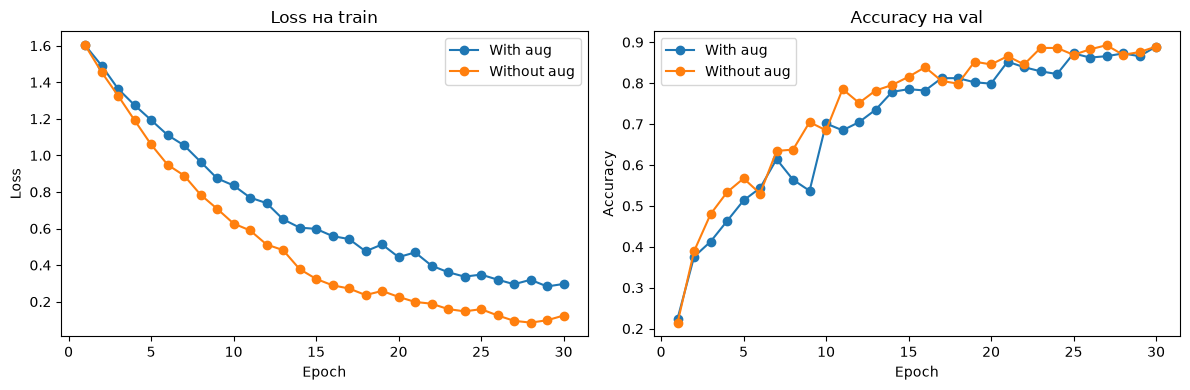

In [49]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), train_loss_aug, marker='o', label='With aug')
plt.plot(range(1, epochs+1), train_loss_history, marker='o', label='Without aug')
plt.title('Loss на train')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), val_acc_aug, marker='o', label='With aug')
plt.plot(range(1, epochs+1), val_acc_history, marker='o', label='Without aug')
plt.title('Accuracy на val')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
results = pd.DataFrame({
    'experiment': ['without_aug', 'with_aug'],
    'best_epoch': [best_epoch, best_epoch_aug],
    'val_accuracy': [best_acc, best_acc_aug],
    'last_val_accuracy': [val_acc_history[-1], val_acc_aug[-1]],
})
print(results.to_string(index=False))

 experiment  best_epoch  val_accuracy  last_val_accuracy
without_aug          27      0.892617           0.889262
   with_aug          30      0.889262           0.889262


**Что мы видим?**

Начнём с левого графика: как меняется loss на train? Если она снижается, модель
учится лучше отвечать на обучающих примерах. Но достаточно ли этого, чтобы
выбрать лучшую модель? Посмотрим на правый график — accuracy на validation.

**В какую эпоху качество было лучшим?**

В таблице `best_epoch` — номер лучшей эпохи, `val_accuracy` — её точность,
а `last_val_accuracy` — точность после последней эпохи. Если loss продолжает
снижаться, а val accuracy уже падает, это признак переобучения: запоминание
train не даёт такого же улучшения на новых изображениях. Поэтому мы сохраняли
лучшие веса, а не просто брали последнюю модель.

**Что изменили аугментации?**

Сравните два опыта при одинаковом числе эпох. С аугментациями модель видит
более разнообразные и иногда более сложные изображения, поэтому train loss
может быть выше. Это само по себе не означает, что модель хуже: loss теперь
считается на изменённых картинках. Для сравнения у нас есть одна и та же validation
без случайных преобразований. Стал ли выше максимум accuracy? Позже ли он
достигнут? Что происходит к последней эпохе?

**Пример разбора полного запуска**

В проверочном запуске на CPU с seed=42 и 15 эпохами без аугментаций лучшая
val accuracy была 0.7544 на эпохе 9,
а после последней эпохи — 0.7404.
С аугментациями максимум составил 0.7848 на эпохе
15, после последней эпохи — 0.7848.
По нашему правилу выбираем лучшие веса модели с аугментациями.

В этом опыте аугментации повысили лучшую val accuracy на 3.04
процентного пункта. Более высокая loss на изменённых train-картинках сама по себе
не мешает получить лучшее качество на неизменной validation.

Обратите внимание на опыт без аугментаций: после лучшей эпохи train loss
снизилась с 0.3149
до 0.0921 к концу обучения,
но val accuracy стала ниже максимума.
Это как раз тот случай, когда меньшая ошибка на train не означает лучшего
обобщения. Сохранение лучших весов здесь влияет на то, какую модель мы получим.

Это результат одного запуска, а не обещание таких же чисел в другом окружении.
Сверьте этот разбор со своими кривыми и таблицей: если они отличаются,
вывод о выборе модели делайте по своим результатам.

Для учебного CSV выберем лучшую val accuracy среди обоих опытов и всех их эпох.
При равенстве оставим опыт без аугментаций. Теперь перейдём к сохранению модели
и созданию файла с предсказаниями для тестовой выборки.

## Сохранение модели и файла с предсказаниями

Для участия в соревновании нужно сформировать CSV-файл с предсказаниями для тестовой
выборки. Покажем этот шаг на CIFAR-10. Формат нашего **учебного** файла:

- `id` — идентификатор изображения, например `cifar10_00000`;
- `label` — предсказанный класс CIFAR-10 (целое число от 0 до 9).

В CIFAR-10 готовые ID не заданы, поэтому будем использовать индекс изображения
в официальной тестовой части. Файл назовём `cifar10_predictions.csv`:
его нельзя отправлять в контест, где другие изображения, ID и классы.

**План действий:**

1. Выбрать модель по лучшей val accuracy из двух опытов и сохранить её лучшие веса.
2. Загрузить эти веса и тестовые изображения с теми же преобразованиями, что и для validation.
3. Сделать предсказания, сохраняя ID рядом с каждым ответом.
4. Сформировать DataFrame с колонками `id` и `label`, проверить и сохранить в CSV.

Не выбираем модель по test. Сохраним веса и настройки преобразований вместе,
чтобы повторить предсказания после перезапуска. При равной val accuracy оставим
опыт без аугментаций.

**Зачем нужен собственный класс Dataset?**

Обычный `CIFAR10` возвращает пару «изображение, метка». Для создания CSV нам
нужна пара «изображение, ID». Напишем простой `TestDataset`, который наследуется
от `torch.utils.data.Dataset` и оборачивает тестовую часть CIFAR-10. Он будет:

- хранить исходный датасет и список ID;
- по индексу брать изображение, игнорируя метку;
- возвращать изображение и его ID.

Этот класс позволит нам итерироваться по тестовой выборке с помощью `DataLoader`
и одновременно сохранять ID, чтобы правильно сформировать файл с предсказаниями.
Как перейти к изображениям в обычных файлах, разберём в советах
по работе с данными соревнования в конце ноутбука.

In [ ]:
selected_model = model_aug if best_acc_aug > best_acc_cifar else model
checkpoint = {
    'state_dict': selected_model.state_dict(),
    'num_classes': 10,
    'image_size': 32,
    'transform': 'ToTensor',
    'classes': classes,
    'seed': seed,
    'best_epoch': best_epoch_aug if best_acc_aug > best_acc_cifar else best_epoch_cifar,
    'val_accuracy': max(best_acc_cifar, best_acc_aug),
}
torch.save(checkpoint, 'selected_cifar10.pt')
checkpoint = torch.load('selected_cifar10.pt', map_location=device, weights_only=True)
selected_model = CNN(num_classes=checkpoint['num_classes']).to(device)
selected_model.load_state_dict(checkpoint['state_dict'])

<All keys matched successfully>

In [19]:
class TestDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset
        self.ids = [f'cifar10_{index:05d}' for index in range(len(dataset))]

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, _ = self.dataset[index]  # Метка не участвует в предсказании.
        return image, self.ids[index]

Преобразования для тестовой выборки должны быть такими же, как для validation.
В нашем примере это только `ToTensor`: размер изображений уже 32×32, нормализацию
мы не добавляли. Аугментации при итоговой оценке не применяем.

Создадим DataLoader с изображениями и ID. Метки CIFAR-10 понадобятся только
после получения CSV, чтобы один раз оценить итоговое качество выбранной модели.
В тестовой части соревнования меток у вас не будет.

In [20]:
assert checkpoint['image_size'] == 32 and checkpoint['transform'] == 'ToTensor'
test_dataset_cifar.transform = transforms.ToTensor()
test_dataset = TestDataset(test_dataset_cifar)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)

print(f"Test size: {len(test_dataset)}")

Test size: 10000


Из цикла обучения берём только часть с оценкой, чтобы получить предсказания

In [21]:
# Переводим модель в режим оценки
selected_model.eval()

test_ids = []
test_preds = []

with torch.no_grad():
    for inputs, ids in test_loader:
        inputs = inputs.to(device)
        outputs = selected_model(inputs)
        _, preds = torch.max(outputs, 1)
        test_preds.extend(preds.cpu().numpy())
        # ID сохраняем из того же батча, что и предсказания
        test_ids.extend(ids)

In [22]:
# Создаём DataFrame и проверяем формат учебного CSV
submission = pd.DataFrame({'id': test_ids, 'label': test_preds})
assert submission['id'].is_unique and set(submission['id']) == set(test_dataset.ids)
assert len(submission) == len(test_dataset) == 10000
assert submission['label'].between(0, 9).all()
assert pd.api.types.is_integer_dtype(submission['label'])
submission = submission.set_index('id').loc[test_dataset.ids].reset_index()
submission.to_csv('cifar10_predictions.csv', index=False)
print("Файл cifar10_predictions.csv сохранён")
print(submission.head())

# Итоговая оценка CIFAR-10 после выбора модели по validation
test_labels = pd.Series(test_dataset_cifar.targets, index=test_dataset.ids)
correct = submission['label'].to_numpy() == test_labels.loc[submission['id']].to_numpy()
print(f"CIFAR-10: итоговая test accuracy = {correct.mean():.4f}")

Файл cifar10_predictions.csv сохранён
              id  label
0  cifar10_00000      5
1  cifar10_00001      8
2  cifar10_00002      8
3  cifar10_00003      0
4  cifar10_00004      6
CIFAR-10: итоговая test accuracy = 0.7790


Мы рассмотрели полный цикл решения на CIFAR-10: от загрузки данных и построения
CNN до сохранения модели и получения файла с предсказаниями.

## Теперь ваша очередь: данные соревнования

В соревновании нужно самостоятельно построить такой же рабочий процесс для
других изображений. В выданном наборе `mri_classification_dataset`:

- `train/class_0` … `train/class_4` — 1390 обучающих изображений;
- `val/class_0` … `val/class_4` — 298 изображений для выбора модели;
- `test` — 300 изображений без доступных меток;
- `sample_submission.csv` — образец CSV с колонками `id,label`. Нули в нём — заглушки.

**Что предстоит сделать самостоятельно?**

1. Посмотреть изображения и размеры, проверить соответствие `class_0` → 0, …,
   `class_4` → 4. Для размеченных папок подойдёт `torchvision.datasets.ImageFolder`:
   его работу разберём ниже на десяти учебных картинках. Для `test` напишите свой Dataset,
   который открывает изображение и возвращает его вместе с ID.
2. Выбрать размер входа и преобразования. Изображения контеста имеют размер
   256×256 или 512×512; при изменении входного размера пересчитайте размер
   карты признаков перед `Linear`. Сколько выходов должно быть у вашей CNN?
3. Обучить CNN с нуля, выбирая лучшую эпоху по val accuracy. Проверить отдельным
   опытом, помогают ли выбранные аугментации, и объяснить результат по графикам.
4. Сохранить выбранную модель вместе с преобразованиями и соответствием классов.
   После загрузки весов получить предсказания для всех test-изображений.
5. Создать `submission.csv`: `id` — имя test-файла без расширения, `label` —
   целое число от 0 до 4. Проверить, что все ID из `sample_submission.csv`
   встречаются ровно один раз; порядок строк не важен. Подготовить исполняемый
   notebook с описанием своих экспериментов.

В решении контеста разрешены только выданные данные и обучение CNN с нуля. Не переносите в решение веса, обученные на CIFAR-10.
Предобученные веса, ручная разметка test и обмен ответами запрещены.
Порог accuracy ≥ 0.85 — цель самостоятельной работы;
качество на CIFAR-10 не говорит о прохождении этого порога.

Ниже разберём работу с файлами и идеи для отдельных экспериментов.

## Советы по работе с данными соревнования

В контесте изображения лежат в обычных папках и имеют разные размеры.
Разберём нужные приёмы на нескольких уже знакомых картинках CIFAR-10.

**А если изображения лежат в обычных файлах?**

`CIFAR10` уже знает, как устроен учебный набор, и сам загружает изображения и метки.
Но часто данные выдают просто в папках. Как работать с ними?

Для загрузки данных из папок с подпапками по классам удобно использовать
`torchvision.datasets.ImageFolder`. Он автоматически присвоит метки классам
в алфавитном порядке папок. Соответствие можно посмотреть в `class_to_idx`.

Посмотрим на маленьком примере. Сохраним по одному изображению из каждого класса
**обучающей части** CIFAR-10 в PNG-файлы: например,
`cifar10_examples/airplane/airplane.png` и `cifar10_examples/frog/frog.png`.
`ImageFolder` определит класс по подпапке, а не по имени самого файла.
Затем загрузим эти же изображения с помощью `ImageFolder`.

Это десять картинок для знакомства с загрузкой из файлов. В опытах выше
мы обучались на всех 45000 изображениях `train_dataset_cifar`.

**А как написать свой Dataset для test?**

В примере ниже откроем картинку через `Image.open`, приведём её к RGB
и получим ID через `Path.stem`.
В файловом Dataset эти действия выполняются в `__getitem__`: берём путь по
индексу, открываем изображение, применяем преобразования и возвращаем тензор
вместе с ID. Список путей удобно один раз собрать в `__init__`.
`ImageFolder` для папки без подпапок классов не подойдёт — именно такой
загрузчик вам предстоит написать для test соревнования.

In [23]:
# Создадим маленький файловый пример из уже загруженного train CIFAR-10.
demo_dir = Path('cifar10_examples')
for label, class_name in enumerate(classes):
    index = next(i for i in train_dataset_cifar.indices
                 if train_dataset_cifar.dataset.targets[i] == label)
    image_tensor, _ = train_dataset_cifar.dataset[index]
    class_dir = demo_dir / class_name
    class_dir.mkdir(parents=True, exist_ok=True)
    transforms.ToPILImage()(image_tensor).save(class_dir / f'{class_name}.png')

file_dataset = datasets.ImageFolder(demo_dir, transform=transforms.ToTensor())
print('Соответствие классов:', file_dataset.class_to_idx)

# Отдельное изображение можно открыть и без ImageFolder.
example_path = Path(file_dataset.samples[0][0])
with Image.open(example_path) as image:
    example_image = image.convert('RGB')
file_tensor = transforms.ToTensor()(example_image)
print('ID из имени файла:', example_path.stem)
print('Размер тензора:', file_tensor.shape)

Соответствие классов: {'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}
ID из имени файла: airplane
Размер тензора: torch.Size([3, 32, 32])


**Зачем изменять размер изображения?**

В CIFAR-10 все изображения уже имеют размер 32×32. В другом наборе размеры могут
различаться, а для обычного батча нам нужны тензоры одинаковой формы.
`transforms.Resize((height, width))` приводит их к выбранному размеру.
Больший вход требует больше вычислений; уменьшение изображения может потерять
мелкие детали. Размер входа — одно из решений, которые нужно проверять на validation.

**Что делает нормализация?**

После `ToTensor()` значения пикселей находятся в диапазоне [0, 1].
`Normalize(mean, std)` отдельно для каждого цветового канала вычисляет
`normalized = (original - mean) / std`. Три числа в `mean` и `std`
соответствуют каналам RGB.

Для наглядности возьмём `mean = std = [0.5, 0.5, 0.5]`: тогда значения [0, 1]
перейдут в [-1, 1]. Это выбранные для примера числа, а не вычисленные статистики
CIFAR-10; они не делают среднее нашего набора равным нулю, а дисперсию — единице.
Если решите оценить среднее и стандартное отклонение по данным, используйте только
train и затем применяйте те же значения к validation и test.

**Как показать нормализованное изображение?**

Перед визуализацией выполняем обратное преобразование:
`original = normalized * std + mean`. С помощью `view(3, 1, 1)` превращаем
три числа для RGB в тензор, который можно применять к изображению формы `(3, H, W)`.
После этого `permute(1, 2, 0)` меняет порядок осей на `(H, W, C)` для matplotlib.

Покажем оба преобразования на сохранённой картинке. Размер 64×64 здесь выбран
только для демонстрации: увеличение не восстанавливает детали исходного CIFAR-10.
В двух опытах обучения выше мы использовали 32×32 и `ToTensor()`. Добавление
нормализации можно проверить отдельным экспериментом.

Размер после Resize: torch.Size([3, 64, 64])
Диапазон после Normalize: [-0.96, 0.93]


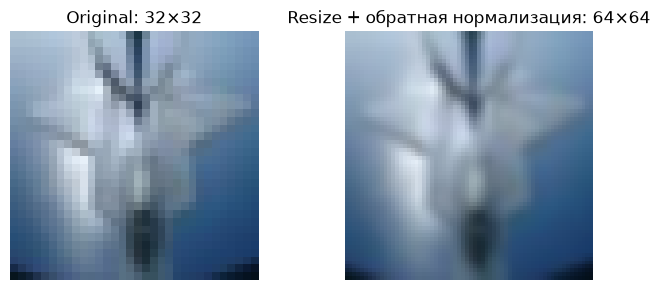

In [24]:
demo_mean = [0.5, 0.5, 0.5]
demo_std = [0.5, 0.5, 0.5]
demo_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(demo_mean, demo_std),
])
normalized = demo_transform(example_image)
restored = (normalized * torch.tensor(demo_std).view(3, 1, 1)
            + torch.tensor(demo_mean).view(3, 1, 1))
print('Размер после Resize:', normalized.shape)
print(f'Диапазон после Normalize: [{normalized.min():.2f}, {normalized.max():.2f}]')

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(example_image)
axes[0].set_title('Original: 32×32')
axes[1].imshow(restored.permute(1, 2, 0).numpy())
axes[1].set_title('Resize + обратная нормализация: 64×64')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Идеи для улучшения

Наш учебный пример — это простая CNN для CIFAR-10, обученная с нуля. Его можно улучшить разными способами. Ниже перечислены направления для отдельных экспериментов. Выбирайте изменения по validation, не по частым проверкам test. Для самостоятельного решения соблюдайте ограничения соревнования, перечисленные выше.

### 1. Аугментации данных

**Идея.**  
Мы использовали минимальный набор аугментаций: случайное отражение, небольшой поворот, лёгкое изменение яркости и контраста. Можно попробовать более разнообразные преобразования, чтобы модель стала ещё устойчивее.

**Что можно добавить:**

- Случайное кадрирование с последующим масштабированием (`RandomResizedCrop`) — делает модель инвариантнее к положению объекта.
- Увеличить диапазон поворота, например, до 20 градусов.
- Добавить случайное вертикальное отражение (но для медицинских изображений это может быть нежелательно, поэтому проверяйте).
- Использовать более сильные изменения яркости, контраста, насыщенности.
- Попробовать продвинутые методы, такие как MixUp или CutMix (реализованы в библиотеке `timm`).

---

### 2. Test-Time Augmentation (TTA)

**Идея.**  
Обычно аугментации применяются только при обучении. Но можно использовать их и на этапе предсказания. Для каждого тестового изображения мы делаем несколько его случайных преобразований, получаем предсказания для каждого варианта и усредняем вероятности. Это уменьшает случайную ошибку и часто повышает точность.

**Как это сделать.**  
Нужно изменить цикл предсказания: для каждого батча тестовых изображений генерировать несколько аугментированных копий (например, 5), прогонять их через модель, собирать вероятности, усреднять и затем выбирать класс.

---

### 3. Ансамблирование

**Идея.**  
Ансамблирование — это комбинирование предсказаний нескольких моделей. Один из простых и эффективных способов — обучить несколько моделей с разными случайными seed и усреднить их предсказания.

**Почему разные seed дают разные модели?**  
Seed влияет на начальную инициализацию весов, порядок перемешивания данных и случайные аугментации. Поэтому модели получаются разными и могут ошибаться по-разному. Усреднение их ответов сглаживает ошибки и часто улучшает результат.

**Как это сделать практически.**  
Обучите модель несколько раз, меняя seed перед фиксацией (например, 42, 666, 1337). Для каждой модели получите предсказания на тесте. Затем усредните вероятности и выберите класс с наибольшим средним значением. Перед усреднением вероятностей примените softmax к логитам. Усреднение логитов даёт другой ансамбль; какой способ лучше, проверяют на validation.

---

### 4. Настройка гиперпараметров

**Идея.**  
Гиперпараметры — это параметры, которые не обучаются автоматически, а задаются вручную: learning rate, batch size, количество эпох, dropout, тип оптимизатора. Их подбор может заметно улучшить качество.

**Что можно менять:**

- **learning rate** — например, попробовать 1e-3, 5e-4, 1e-4. Слишком большой lr приводит к нестабильному обучению, слишком маленький — к медленной сходимости.
- **batch size** — 16, 32, 64. Влияет на шум градиента и использование памяти.
- **количество эпох** — иногда модель продолжает улучшаться после 15 эпох, но возможен и переобучающий эффект.
- **dropout** — добавить слой Dropout и подобрать его вероятность; в нашей CIFAR CNN его пока нет.
- **оптимизатор** — попробовать AdamW или SGD с моментом.

**Планировщик learning rate.**  
Полезный инструмент — автоматическое уменьшение learning rate в процессе обучения. В PyTorch есть готовые планировщики: `CosineAnnealingLR`, `ReduceLROnPlateau` и др. Они помогают точнее сойтись к минимуму.

**Как это сделать.**  
Измените соответствующие параметры в коде, добавьте планировщик перед циклом обучения и вызывайте его шаг после каждой эпохи (или после оценки на валидации).

**Ожидаемый эффект.**  
Зависит от данных и настроек; прирост проверяется экспериментом, а не гарантируется.

---

### 5. Псевдо-лейблинг

**Идея.**  
Псевдо-лейблинг — это метод, при котором мы используем предсказания модели на неразмеченных данных (в нашем случае — на тестовой выборке) как дополнительные обучающие примеры с «псевдо-метками».

**Как это работает.**  
Сначала обучаем модель на размеченных данных (`train`). Затем делаем предсказания для тестовых изображений и отбираем те, в которых модель уверена больше всего (например, вероятность правильного класса выше 0.95). Добавляем эти изображения с их предсказанными метками в обучающую выборку и обучаем модель заново.

**На что обратить внимание.**  
- Порог уверенности нужно подбирать: слишком низкий добавит много ошибочных меток, слишком высокий — мало новых данных.
- Псевдо-лейблинг может как улучшить, так и ухудшить результат. Если модель ошибается в уверенных предсказаниях, ошибки закрепятся.
- В условиях соревнования, где тестовая выборка используется для оценки, этот метод может привести к переобучению под конкретный тест. Поэтому использовать его нужно осторожно и скорее в учебных целях.

# Заключение

Вы прошли весь путь от загрузки данных до файла с предсказаниями на CIFAR-10. Теперь примените эти шаги к данным соревнования самостоятельно. Желаем успехов в соревновании!

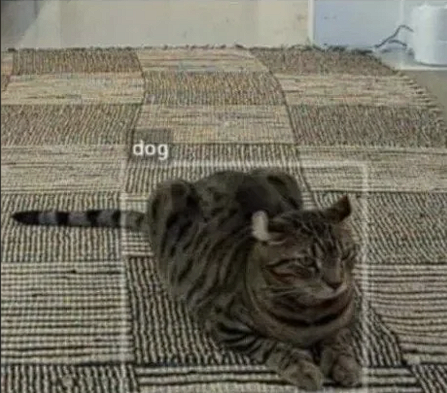